# Sankey Diagram (Customer Lifecycle Transition Flow)

## Исходные данные для построения

- датафрейм

In [6]:
all_transitions = pd.read_csv('all_transitions.csv')
all_transitions

,card,Lifecycle_Stage_from,Monetary_from,Lifecycle_Stage_to,Monetary_to,Revenue_Change,Period
0,2000200195023,Loyal,18068.0,Loyal,15067.0,-3001.0,2021-12-31 -> 2022-01-31
1,2000200193494,At Risk,747.0,At Risk,0.0,-747.0,2021-12-31 -> 2022-01-31
2,2000200199106,Loyal,19535.0,Loyal,19535.0,0.0,2021-12-31 -> 2022-01-31
3,2000200168768,Active,54.0,At Risk,54.0,0.0,2021-12-31 -> 2022-01-31
4,2000200226314,Active,1733.0,At Risk,1733.0,0.0,2021-12-31 -> 2022-01-31
...,...,...,...,...,...,...,...
21873,2000200245063,New,739.0,New,1282.0,543.0,2022-04-30 -> 2022-05-31
21874,2000200245070,New,530.0,New,530.0,0.0,2022-04-30 -> 2022-05-31
21875,2000200245087,New,550.0,New,550.0,0.0,2022-04-30 -> 2022-05-31
21876,2000200238133,New,952.0,New,3867.0,2915.0,2022-04-30 -> 2022-05-31


## Код для построения

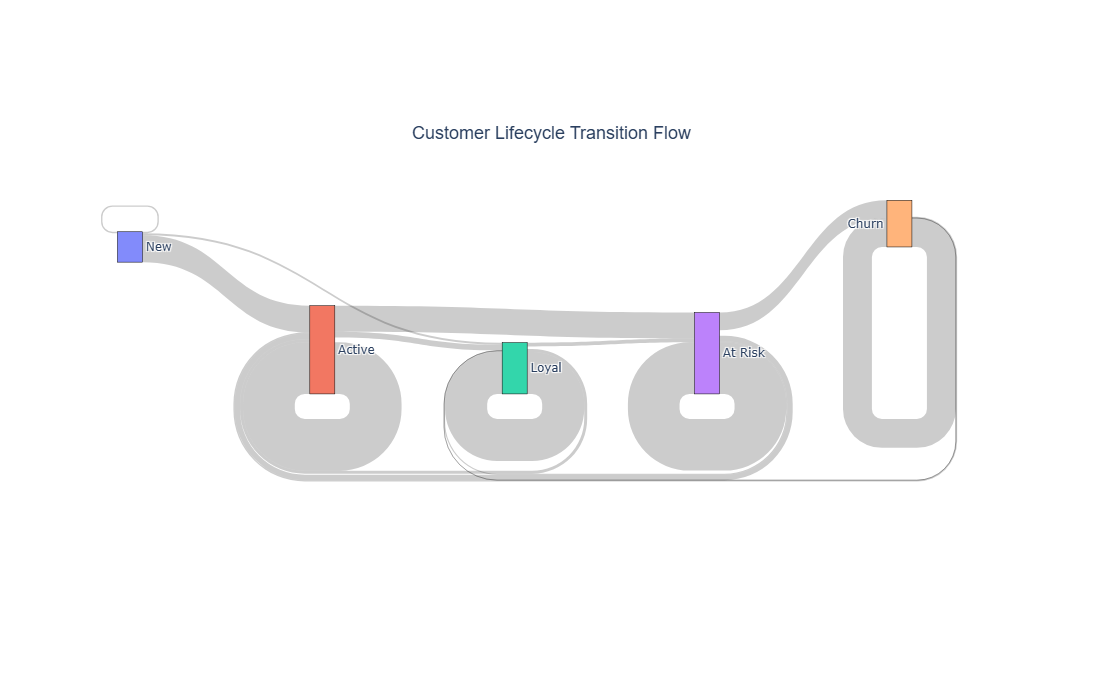

In [7]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import plotly.graph_objects as go

# =====================================================
# LOAD DATA
# =====================================================

all_transitions = pd.read_csv('all_transitions.csv')

# ---------------------------------------------
# AGGREGATE TRANSITIONS
# ---------------------------------------------

sankey_data = (
    all_transitions
    .groupby([
        'Lifecycle_Stage_from',
        'Lifecycle_Stage_to'
    ])
    .size()
    .reset_index(name='count')
)

# ---------------------------------------------
# STAGE LABELS
# ---------------------------------------------

stages = [
    'New',
    'Active',
    'Loyal',
    'At Risk',
    'Churn'
]

# create index mapping
stage_to_idx = {
    stage: idx
    for idx, stage in enumerate(stages)
}

# ---------------------------------------------
# BUILD LINKS
# ---------------------------------------------

source = sankey_data['Lifecycle_Stage_from'].map(stage_to_idx)

target = sankey_data['Lifecycle_Stage_to'].map(stage_to_idx)

value = sankey_data['count']

# ---------------------------------------------
# SANKEY FIGURE
# ---------------------------------------------

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=20,
                thickness=25,
                line=dict(color='black', width=0.5),
                label=stages
            ),

            link=dict(
                source=source,
                target=target,
                value=value
            )
        )
    ]
)

# ---------------------------------------------
# LAYOUT
# ---------------------------------------------

fig.update_layout(
    title=dict(
        text='Customer Lifecycle Transition Flow',
        font = dict(size=18,family="Arial"),
        y=0.82,                    # ← опускаем ниже (0 = низ, 1 = верх)
        x=0.5,),
    height=700,
    width=1000
)
#fig.write_html("customer_lifecycle_transition_flow.html")
fig.show()

In [8]:
sankey_data

,Lifecycle_Stage_from,Lifecycle_Stage_to,count
0,Active,Active,4211
1,Active,At Risk,2113
2,Active,Loyal,479
3,At Risk,Active,436
4,At Risk,At Risk,4202
5,At Risk,Churn,1446
6,At Risk,Loyal,92
7,Churn,Active,105
8,Churn,Churn,2353
9,Churn,Loyal,1


In [9]:
stage_to_idx

{'New': 0, 'Active': 1, 'Loyal': 2, 'At Risk': 3, 'Churn': 4}

In [10]:
source

0     1
1     1
2     1
3     3
4     3
5     3
6     3
7     4
8     4
9     4
10    2
11    2
12    2
13    0
14    0
15    0
Name: Lifecycle_Stage_from, dtype: int64

In [11]:
target

0     1
1     3
2     2
3     1
4     3
5     4
6     2
7     1
8     4
9     2
10    1
11    3
12    2
13    1
14    2
15    0
Name: Lifecycle_Stage_to, dtype: int64

In [12]:
value

0     4211
1     2113
2      479
3      436
4     4202
5     1446
6       92
7      105
8     2353
9        1
10     242
11     307
12    3419
13    2179
14     181
15     112
Name: count, dtype: int64